[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/orthogonality-and-gram-schmidt/notebook.ipynb)

# Orthogonality and Gram-Schmidt: hands-on

This notebook goes with the [topic README](README.md). You will test vectors for orthogonality, check the orthogonal pairs among the four fundamental subspaces, compute coordinates in an orthonormal basis with plain dot products, watch orthogonal matrices preserve lengths and angles, write Gram-Schmidt from scratch with a printed trace, compare it with `numpy.linalg.qr`, see classical Gram-Schmidt lose orthogonality, and simulate why random high-dimensional vectors are nearly orthogonal. It uses NumPy, Matplotlib, and `scipy.linalg`, and runs in a few seconds on a CPU.

A note on numbers: orthogonality checks on a computer only hold **up to rounding error**. We always compare with `np.allclose`, never with `==`.

In [1]:
%matplotlib inline
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=4, suppress=True)

## 1. Orthogonal vectors and Pythagoras

Two vectors are **orthogonal** when their dot product is zero. For orthogonal vectors, the squared length of the sum equals the sum of the squared lengths (Pythagoras).

v . w = 0.0 -> orthogonal? True
|v|^2 + |w|^2 = 50.0   |v + w|^2 = 50.0
(1,2,3) and (3,0,-1) orthogonal? True
(1,2,3) and (1,1,1) orthogonal? False


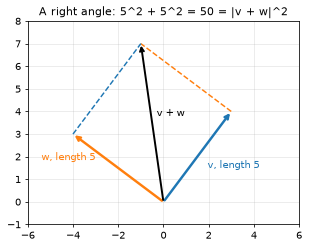

In [2]:
def orthogonal(u, v):
    """True if u . v is zero, up to rounding error."""
    return np.isclose(np.dot(u, v), 0.0)


v = np.array([3.0, 4.0])
w = np.array([-4.0, 3.0])
print("v . w =", v @ w, "-> orthogonal?", orthogonal(v, w))
print("|v|^2 + |w|^2 =", v @ v + w @ w, "  |v + w|^2 =", (v + w) @ (v + w))

u = np.array([1.0, 2.0, 3.0])
print("(1,2,3) and (3,0,-1) orthogonal?", orthogonal(u, np.array([3.0, 0.0, -1.0])))
print("(1,2,3) and (1,1,1) orthogonal?", orthogonal(u, np.array([1.0, 1.0, 1.0])))

fig, ax = plt.subplots(figsize=(5, 5))
ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C0", lw=2.5))
ax.annotate("", xy=w, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C1", lw=2.5))
ax.annotate("", xy=v + w, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k", lw=2))
ax.plot([v[0], (v + w)[0]], [v[1], (v + w)[1]], color="C1", ls="--")
ax.plot([w[0], (v + w)[0]], [w[1], (v + w)[1]], color="C0", ls="--")
ax.text(*(v * 0.55 + [0.3, -0.7]), "v, length 5", color="C0")
ax.text(*(w * 0.55 + [-3.2, 0.2]), "w, length 5", color="C1")
ax.text(*((v + w) * 0.5 + [0.2, 0.3]), "v + w", color="k")
ax.set_xlim(-6, 6); ax.set_ylim(-1, 8); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_title("A right angle: 5^2 + 5^2 = 50 = |v + w|^2")
plt.show()

## 2. The four fundamental subspaces are orthogonal in pairs

For a matrix $A$, every vector in the nullspace has dot product zero with every row, so **the nullspace is orthogonal to the row space**. In the same way, **the left nullspace is orthogonal to the column space**. Here we compute bases for all four subspaces of a $3 \times 4$ matrix and test every pair of basis vectors. A matrix of dot products that is all (nearly) zero means the two subspaces are orthogonal.

In [3]:
A = np.array([[1, 2, 1, 3],
              [2, 4, 3, 8],
              [3, 6, 4, 11]])
m, n = A.shape
r = np.linalg.matrix_rank(A)

row_space = sla.orth(A.T)           # columns: an orthonormal basis for the row space (in R^n)
null_space = sla.null_space(A)      # basis for the nullspace (in R^n)
col_space = sla.orth(A)             # basis for the column space (in R^m)
left_null = sla.null_space(A.T)     # basis for the left nullspace (in R^m)

print(f"A is {m} x {n}, rank {r}")
print("dimensions: row", row_space.shape[1], "+ null", null_space.shape[1], "=", n, "(= n)")
print("dimensions: col", col_space.shape[1], "+ left null", left_null.shape[1], "=", m, "(= m)")

print("\nrow space . nullspace dot products:\n", np.round(row_space.T @ null_space, 10) + 0.0)
print("all zero up to rounding?", np.allclose(row_space.T @ null_space, 0))
print("column space . left nullspace all zero?", np.allclose(col_space.T @ left_null, 0))

A is 3 x 4, rank 2
dimensions: row 2 + null 2 = 4 (= n)
dimensions: col 2 + left null 1 = 3 (= m)

row space . nullspace dot products:
 [[0. 0.]
 [0. 0.]]
all zero up to rounding? True
column space . left nullspace all zero? True


A $2 \times 3$ matrix makes the picture easy to see in 3D. Its row space is a plane, and its nullspace is the line sticking out of that plane at a right angle.

nullspace direction: [ 1. -2.  1.] | dot with each row: [0. 0.]


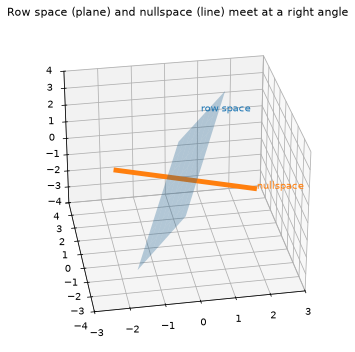

In [4]:
B = np.array([[1, 1, 1],
              [1, 2, 3]])
n_dir = sla.null_space(B).ravel()
n_dir = n_dir / n_dir[0]                  # scale to (1, -2, 1)
print("nullspace direction:", n_dir, "| dot with each row:", np.round(B @ n_dir, 10) + 0.0)

s, t = np.meshgrid(np.linspace(-0.8, 0.8, 8), np.linspace(-0.8, 0.8, 8))
plane = s[..., None] * B[0] + t[..., None] * B[1]       # the row space: all combinations of the rows
line = np.linspace(-1.6, 1.6, 30)[:, None] * n_dir

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(plane[..., 0], plane[..., 1], plane[..., 2], alpha=0.3, color="C0")
ax.plot(*line.T, color="C1", lw=5)
ax.text(*(n_dir * 1.65), "nullspace", color="C1")
ax.text(*(B[1] * 0.75 + [0, 0, 0.5]), "row space", color="C0")
ax.view_init(elev=30, azim=-100)
ax.set_xlim(-3, 3); ax.set_ylim(-4, 4); ax.set_zlim(-4, 4)
ax.set_title("Row space (plane) and nullspace (line) meet at a right angle")
plt.show()

## 3. Coordinates in an orthonormal basis are dot products

For an **orthonormal** basis (perpendicular unit vectors), the coordinates of $\mathbf{v}$ are simply $c_i = \mathbf{q}_i \cdot \mathbf{v}$. For a general basis we had to solve a linear system. Here both give the same answer.

In [5]:
angle = np.radians(30)
q1 = np.array([np.cos(angle), np.sin(angle)])
q2 = np.array([-np.sin(angle), np.cos(angle)])
Q = np.column_stack([q1, q2])
print("Q^T Q =\n", Q.T @ Q)
print("Q^T Q is the identity:", np.allclose(Q.T @ Q, np.eye(2)))

v = np.array([5.0, 1.0])
c_dots = np.array([q1 @ v, q2 @ v])            # coordinates by dot products
c_solve = np.linalg.solve(Q, v)                # coordinates by solving Q c = v
print("by dot products:", c_dots)
print("by solving     :", c_solve)
print("rebuilt v      :", c_dots[0] * q1 + c_dots[1] * q2)

Q^T Q =
 [[1. 0.]
 [0. 1.]]
Q^T Q is the identity: True
by dot products: [ 4.8301 -1.634 ]
by solving     : [ 4.8301 -1.634 ]
rebuilt v      : [5. 1.]


## 4. Orthogonal matrices preserve lengths and angles

A square matrix $Q$ with orthonormal columns is an **orthogonal matrix**: $Q^\top Q = I$, so $Q^{-1} = Q^\top$. It preserves lengths, dot products, and therefore angles. Rotations and reflections are examples. We draw a simple house shape before and after.

rotation: Q^T Q = I? True | det = +1
reflection: Q^T Q = I? True | det = -1

|x| = 5.0 |Q x| = 5.0
x . y = 11.0  (Qx) . (Qy) = 11.0


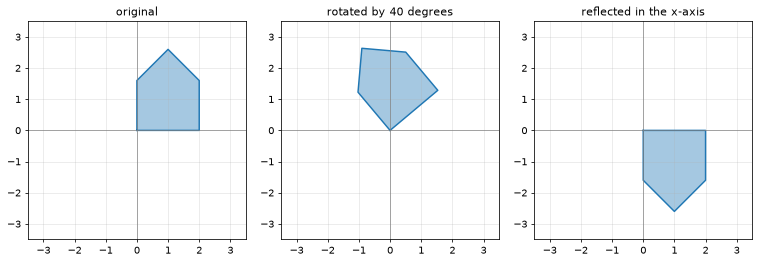

In [6]:
house = np.array([[0, 2, 2, 1, 0, 0],
                  [0, 0, 1.6, 2.6, 1.6, 0]])        # 2 x 6: corner points as columns

theta = np.radians(40)
rotation = np.array([[np.cos(theta), -np.sin(theta)],
                     [np.sin(theta),  np.cos(theta)]])
reflection = np.array([[1, 0],
                       [0, -1]])                    # mirror in the x-axis

for name, Qm in [("rotation", rotation), ("reflection", reflection)]:
    print(f"{name}: Q^T Q = I? {np.allclose(Qm.T @ Qm, np.eye(2))} | det = {np.linalg.det(Qm):+.0f}")

x = np.array([3.0, 4.0]); y = np.array([1.0, 2.0])
print("\n|x| =", np.linalg.norm(x), "|Q x| =", np.linalg.norm(rotation @ x))
print("x . y =", x @ y, " (Qx) . (Qy) =", round((rotation @ x) @ (rotation @ y), 10))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (pts, title) in zip(axes, [(house, "original"), (rotation @ house, "rotated by 40 degrees"),
                                   (reflection @ house, "reflected in the x-axis")]):
    ax.fill(pts[0], pts[1], alpha=0.4); ax.plot(pts[0], pts[1], lw=1.5)
    ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.axhline(0, color="gray", lw=0.7); ax.axvline(0, color="gray", lw=0.7)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_title(title)
plt.tight_layout()
plt.show()

The house keeps its shape, size, and angles; only its position changes. The determinant is $+1$ for the rotation and $-1$ for the reflection (which flips orientation). A product of orthogonal matrices is orthogonal, which we check next.

In [7]:
product = rotation @ reflection @ rotation
print("product of three orthogonal matrices is orthogonal:", np.allclose(product.T @ product, np.eye(2)))

product of three orthogonal matrices is orthogonal: True


## 5. Gram-Schmidt from scratch

Gram-Schmidt turns independent vectors $\mathbf{a}_1, \mathbf{a}_2, \mathbf{a}_3$ into orthonormal vectors $\mathbf{q}_1, \mathbf{q}_2, \mathbf{q}_3$. For each new vector: subtract its components along the $\mathbf{q}$'s already found, then divide by the length of what is left. The function prints each step. It also records the numbers we computed in a matrix $R$, so that $A = QR$.

In [8]:
def gram_schmidt(A, verbose=False):
    """Classical Gram-Schmidt on the columns of A. Returns Q and R with A = Q R."""
    A = np.array(A, dtype=float)
    m, n = A.shape
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    for j in range(n):
        v = A[:, j].copy()
        for i in range(j):
            R[i, j] = Q[:, i] @ A[:, j]            # component of a_j along q_i
            v -= R[i, j] * Q[:, i]                 # subtract it
            if verbose:
                print(f"  a{j + 1} . q{i + 1} = {R[i, j]:.4f}  -> subtract {R[i, j]:.4f} * q{i + 1}")
        R[j, j] = np.linalg.norm(v)
        if R[j, j] < 1e-12:
            raise ValueError(f"column {j + 1} is dependent on the earlier ones (a zero vector is left)")
        Q[:, j] = v / R[j, j]
        if verbose:
            print(f"q{j + 1} = {Q[:, j]}   (length of what was left: {R[j, j]:.4f})")
    return Q, R


A = np.column_stack([(1, 1, 0), (1, 0, 1), (0, 1, 1)])     # a1, a2, a3 as columns
Q, R = gram_schmidt(A, verbose=True)
print("\nQ =\n", Q)
print("R =\n", R)

q1 = [0.7071 0.7071 0.    ]   (length of what was left: 1.4142)
  a2 . q1 = 0.7071  -> subtract 0.7071 * q1
q2 = [ 0.4082 -0.4082  0.8165]   (length of what was left: 1.2247)
  a3 . q1 = 0.7071  -> subtract 0.7071 * q1
  a3 . q2 = 0.4082  -> subtract 0.4082 * q2
q3 = [-0.5774  0.5774  0.5774]   (length of what was left: 1.1547)

Q =
 [[ 0.7071  0.4082 -0.5774]
 [ 0.7071 -0.4082  0.5774]
 [ 0.      0.8165  0.5774]]
R =
 [[1.4142 0.7071 0.7071]
 [0.     1.2247 0.4082]
 [0.     0.     1.1547]]


In [9]:
print("Q^T Q = I   :", np.allclose(Q.T @ Q, np.eye(3)))
print("A = Q R     :", np.allclose(Q @ R, A))
print("R is upper triangular:", np.allclose(R, np.triu(R)))

# dependent input: a3 = a1 + a2 leaves a zero vector
try:
    gram_schmidt(np.column_stack([(1, 1, 0), (1, 0, 1), (2, 1, 1)]))
except ValueError as error:
    print("\ndependent columns ->", error)

Q^T Q = I   : True
A = Q R     : True
R is upper triangular: True

dependent columns -> column 3 is dependent on the earlier ones (a zero vector is left)


Here is one step in 2D. Starting from $\mathbf{a}_1$ and $\mathbf{a}_2$, the part of $\mathbf{a}_2$ along $\mathbf{q}_1$ is removed, and what is left is perpendicular to $\mathbf{q}_1$.

q1 . left_over = 0.0


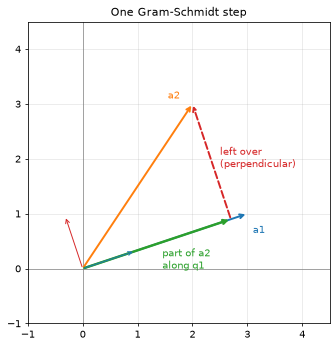

In [10]:
a1 = np.array([3.0, 1.0])
a2 = np.array([2.0, 3.0])
q1 = a1 / np.linalg.norm(a1)
along = (q1 @ a2) * q1                    # the component of a2 along q1
left_over = a2 - along                    # perpendicular to q1
q2 = left_over / np.linalg.norm(left_over)
print("q1 . left_over =", round(q1 @ left_over, 12))

fig, ax = plt.subplots(figsize=(5.6, 5.6))
def arrow(vec, start=(0, 0), color="k", ls="-", lw=2):
    ax.annotate("", xy=np.add(start, vec), xytext=start, arrowprops=dict(arrowstyle="->", color=color, lw=lw, ls=ls))
arrow(a1, color="C0"); arrow(a2, color="C1")
arrow(along, color="C2", lw=2.5)
arrow(left_over, start=along, color="C3", ls="--")
arrow(q1, color="C0", lw=1); arrow(q2, color="C3", lw=1)
ax.text(*(a1 + [0.1, -0.35]), "a1", color="C0"); ax.text(*(a2 + [-0.45, 0.1]), "a2", color="C1")
ax.text(*(along * 0.5 + [0.1, -0.45]), "part of a2\nalong q1", color="C2")
ax.text(*(along + left_over * 0.5 + [0.15, -0.1]), "left over\n(perpendicular)", color="C3")
ax.set_xlim(-1, 4.5); ax.set_ylim(-1, 4.5); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.axhline(0, color="gray", lw=0.7); ax.axvline(0, color="gray", lw=0.7)
ax.set_title("One Gram-Schmidt step")
plt.show()

## 6. QR from NumPy

`numpy.linalg.qr` computes the same factorization with a more reliable method (Householder reflections). The columns of $Q$ may differ from ours by a sign, because $\mathbf{q}_j$ and $-\mathbf{q}_j$ are both valid unit vectors in the same direction line. We can normalise signs by making the diagonal of $R$ positive.

In [11]:
Q_np, R_np = np.linalg.qr(A)
print("NumPy's Q =\n", Q_np)
print("NumPy's R =\n", R_np)

signs = np.sign(np.diag(R_np))              # flip so the diagonal of R is positive
Q_fixed, R_fixed = Q_np * signs, R_np * signs[:, None]
print("\nafter fixing signs: same Q as ours?", np.allclose(Q_fixed, Q), "| same R?", np.allclose(R_fixed, R))

NumPy's Q =
 [[-0.7071  0.4082 -0.5774]
 [-0.7071 -0.4082  0.5774]
 [-0.      0.8165  0.5774]]
NumPy's R =
 [[-1.4142 -0.7071 -0.7071]
 [ 0.      1.2247  0.4082]
 [ 0.      0.      1.1547]]

after fixing signs: same Q as ours? True | same R? True


## 7. When Gram-Schmidt loses orthogonality

In exact arithmetic the output of Gram-Schmidt is perfectly orthonormal. In floating point, rounding errors creep in, and for nearly dependent columns the classical version can fail badly. The **modified** version subtracts each component from the running vector right away, which is much more reliable. Householder QR (what NumPy uses) is better still. The Hilbert matrix, whose columns are almost dependent, is a standard test. We measure how far $Q^\top Q$ is from $I$.

In [12]:
def modified_gram_schmidt(A):
    """Modified Gram-Schmidt: remove each component from the remaining columns immediately."""
    V = np.array(A, dtype=float)
    m, n = V.shape
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    for j in range(n):
        R[j, j] = np.linalg.norm(V[:, j])
        Q[:, j] = V[:, j] / R[j, j]
        for k in range(j + 1, n):
            R[j, k] = Q[:, j] @ V[:, k]
            V[:, k] -= R[j, k] * Q[:, j]
    return Q, R


def orthogonality_error(Q):
    """How far Q^T Q is from the identity (0 would be perfect)."""
    return np.linalg.norm(Q.T @ Q - np.eye(Q.shape[1]))


print(f"{'n':>3} {'classical':>12} {'modified':>12} {'numpy qr':>12}")
for n in (4, 6, 8, 10):
    H = sla.hilbert(n)
    print(f"{n:>3} {orthogonality_error(gram_schmidt(H)[0]):>12.1e} "
          f"{orthogonality_error(modified_gram_schmidt(H)[0]):>12.1e} "
          f"{orthogonality_error(np.linalg.qr(H)[0]):>12.1e}")

  n    classical     modified     numpy qr
  4      4.9e-11      4.2e-13      1.1e-15
  6      2.8e-04      3.5e-10      9.6e-16
  8      1.4e+00      3.6e-07      1.1e-15
 10      3.5e+00      5.2e-05      1.5e-15


Reading the table: for $n = 8$ classical Gram-Schmidt has lost orthogonality completely (an error of order 1), the modified version keeps it to a few millionths, and `np.linalg.qr` stays near $10^{-15}$, the size of rounding error itself. The exact numbers depend on your machine's arithmetic, but the ranking does not.

## 8. Random vectors in high dimensions are nearly orthogonal

Pick two random directions in $d$ dimensions and compute the cosine of the angle between them. In 2D it can be anything. As $d$ grows, the cosine concentrates near 0: random vectors are almost always almost perpendicular. The spread of the cosine is about $1/\sqrt{d}$.

 dimension   std of cosine   1/sqrt(d)
         2          0.7065      0.7071
        10          0.3187      0.3162
       100          0.1000      0.1000
      1000          0.0316      0.0316


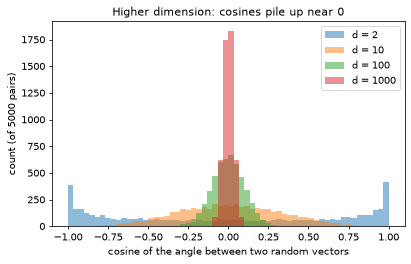

In [13]:
rng = np.random.default_rng(0)
dims = [2, 10, 100, 1000]
cosines = {}
for d in dims:
    u = rng.normal(size=(5000, d))
    v = rng.normal(size=(5000, d))
    cosines[d] = (u * v).sum(axis=1) / (np.linalg.norm(u, axis=1) * np.linalg.norm(v, axis=1))

print(f"{'dimension':>10} {'std of cosine':>15} {'1/sqrt(d)':>11}")
for d in dims:
    print(f"{d:>10} {cosines[d].std():>15.4f} {1 / np.sqrt(d):>11.4f}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for d in dims:
    ax.hist(cosines[d], bins=60, range=(-1, 1), alpha=0.5, label=f"d = {d}")
ax.set_xlabel("cosine of the angle between two random vectors")
ax.set_ylabel("count (of 5000 pairs)")
ax.set_title("Higher dimension: cosines pile up near 0")
ax.legend()
plt.show()

## Recap and next steps

* Vectors are **orthogonal** when $\mathbf{v} \cdot \mathbf{w} = 0$, and then $\|\mathbf{v} + \mathbf{w}\|^2 = \|\mathbf{v}\|^2 + \|\mathbf{w}\|^2$. The row space is orthogonal to the nullspace and the column space to the left nullspace; each pair is a complement of the other.
* For an **orthonormal** basis the coordinates are dot products, $c_i = \mathbf{q}_i \cdot \mathbf{v}$. A square $Q$ with orthonormal columns has $Q^{-1} = Q^\top$ and preserves lengths and angles.
* **Gram-Schmidt** subtracts earlier components and normalises. It gives $A = QR$ with $R$ upper triangular, and a zero vector signals dependent columns.
* In floating point, orthogonality holds only up to rounding; classical Gram-Schmidt can lose it, and modified Gram-Schmidt or Householder QR is used in practice.
* Random vectors in high dimensions are nearly orthogonal.

**Try it yourself:** in section 5, change $\mathbf{a}_3$ to $(1, 1, 1)$ and predict whether the column stays independent before you run it. Then do the [exercises](exercises/problems.md) and the [assignment](assignment.md).

Next topic: [Projections and Least Squares](../projections-and-least-squares/README.md).